In [15]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Konfigurasi path file input dan output
RAW_STOCK_PATH = "../data/raw_data_daily.csv"  # sesuaikan jika berada di folder root: "raw_data_daily.csv"
FX_PATH = "../data/DEXKOUS.csv"                # sesuaikan jika berada di folder root: "DEXKOUS.csv"
OUTPUT_PATH = "../data/nvda_skhy_vix_clean.csv"

In [19]:
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
FIG_DIR = PROJECT_ROOT / 'reports' / 'figures'
TABLE_DIR = PROJECT_ROOT / 'reports' / 'tables'
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

print('folder gambar   :', FIG_DIR)
print('folder tabel    :', TABLE_DIR)


# --- HELPER OTOMATIS SIMPAN GRAFIK & TABEL ---
def save_fig(filename: str, dpi: int = 300):
    """Menyimpan figure matplotlib aktif ke FIG_DIR sebelum plt.show()."""
    filepath = FIG_DIR / filename
    plt.savefig(filepath, dpi=dpi, bbox_inches="tight")
    print(f"[Saved Figure] -> {filepath.relative_to(PROJECT_ROOT)}")


def save_table(df: pd.DataFrame, filename: str, index: bool = True):
    """Menyimpan DataFrame ke CSV (dan Markdown/LaTeX jika perlu) di TABLE_DIR."""
    filepath = TABLE_DIR / filename
    df.to_csv(filepath, index=index)
    print(f"[Saved Table]  -> {filepath.relative_to(PROJECT_ROOT)}")

folder gambar   : c:\Users\ahmdf\Documents\forecast-saham\reports\figures
folder tabel    : c:\Users\ahmdf\Documents\forecast-saham\reports\tables


In [3]:
stocks = pd.read_csv(RAW_STOCK_PATH)
stocks.head()


,Price,Close,Close.1,Close.2,High,High.1,High.2,Low,Low.1,Low.2,Open,Open.1,Open.2,Volume,Volume.1,Volume.2
0,Ticker,000660.KS,NVDA,^VIX,000660.KS,NVDA,^VIX,000660.KS,NVDA,^VIX,000660.KS,NVDA,^VIX,000660.KS,NVDA,^VIX
1,Date,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2022-11-01,81265.171875,13.494420051574707,25.809999465942383,81265.171875,13.875049746891053,26.350000381469727,78843.68284415972,13.470505974860513,25.65999984741211,80102.85714019666,13.761458357625319,25.959999084472656,3820185.0,432817000.0,0.0
3,2022-11-02,81846.34375,13.171579360961914,25.860000610351562,82814.93953402367,14.159024522745352,26.6200008392334,80974.6075443787,13.163608637105877,25.389999389648438,81555.7650147929,13.800316292387196,26.040000915527344,2536363.0,672628000.0,0.0
4,2022-11-03,80102.8515625,13.372855186462402,25.299999237060547,80877.72799841294,13.731564388380816,26.8700008392334,79327.97512658706,12.909524051073214,25.100000381469727,80005.99200801089,12.99621185480263,25.979999542236328,2901380.0,500065000.0,0.0


In [5]:
# 1A. Load data harga saham & VIX
# Normalisasi format file: baris pertama berisi ticker dan baris kedua berisi 'Date'
stocks = stocks.rename(columns={stocks.columns[0]: "Date"})
stocks = stocks.loc[
    stocks["Date"].astype(str).str.match(r"^\d{4}-\d{2}-\d{2}$", na=False)
].copy()
stocks["Date"] = pd.to_datetime(stocks["Date"]).dt.tz_localize(None)
stocks = stocks.sort_values("Date").set_index("Date")

# 1B. Load data kurs USD/KRW (FRED DEXKOUS)
fx = pd.read_csv(FX_PATH)
date_col = fx.columns[0]  # otomatis mendeteksi 'observation_date' atau 'DATE'
fx[date_col] = pd.to_datetime(fx[date_col]).dt.tz_localize(None)
fx = fx.rename(columns={date_col: "Date"}).sort_values("Date").set_index("Date")

# Ubah nilai titik '.' pada hari libur bank AS menjadi NaN, lalu forward-fill maks 2 hari
fx["DEXKOUS"] = pd.to_numeric(fx["DEXKOUS"], errors="coerce").ffill(limit=2)

print(f"Rentang data saham : {stocks.index.min().date()} s.d. {stocks.index.max().date()} ({len(stocks)} baris)")
print(f"Rentang data kurs  : {fx.index.min().date()} s.d. {fx.index.max().date()} ({len(fx)} baris)")
display(stocks.head(3))
display(fx.head(3))

Rentang data saham : 2022-11-01 s.d. 2026-10-30 (1036 baris)
Rentang data kurs  : 2022-11-01 s.d. 2026-10-30 (1044 baris)


,Close,Close.1,Close.2,High,High.1,High.2,Low,Low.1,Low.2,Open,Open.1,Open.2,Volume,Volume.1,Volume.2
Date,,,,,,,,,,,,,,,
2022-11-01,81265.171875,13.494420051574707,25.809999465942383,81265.171875,13.875049746891053,26.350000381469727,78843.68284415972,13.470505974860513,25.65999984741211,80102.85714019666,13.761458357625319,25.959999084472656,3820185.0,432817000.0,0.0
2022-11-02,81846.34375,13.171579360961914,25.860000610351562,82814.93953402367,14.159024522745352,26.6200008392334,80974.6075443787,13.163608637105877,25.389999389648438,81555.7650147929,13.800316292387196,26.040000915527344,2536363.0,672628000.0,0.0
2022-11-03,80102.8515625,13.372855186462402,25.299999237060547,80877.72799841294,13.731564388380816,26.8700008392334,79327.97512658706,12.909524051073214,25.100000381469727,80005.99200801089,12.99621185480263,25.979999542236328,2901380.0,500065000.0,0.0


,DEXKOUS
Date,
2022-11-01,1416.20
2022-11-02,1418.31
2022-11-03,1423.99


In [6]:
# 2. Inner join kalender perdagangan aktif AS (NASDAQ/CBOE) & Korea (KRX)
df = stocks.join(fx[["DEXKOUS"]], how="inner").dropna()

print(f"Jumlah observasi setelah inner join: {len(df)} hari bursa")
print(f"Rentang tanggal efektif            : {df.index.min().date()} s.d. {df.index.max().date()}")

Jumlah observasi setelah inner join: 943 hari bursa
Rentang tanggal efektif            : 2022-11-01 s.d. 2026-10-30


In [9]:
# 3. Deteksi otomatis nama kolom & konversi SK Hynix (KRW -> USD)
skhy_col = "000660.KS" if "000660.KS" in df.columns else "SKHY"
vix_col = "^VIX" if "^VIX" in df.columns else "VIX"

# Gunakan nama ticker jika tersedia, atau nama kolom aktual dari file
skhy_col = next((c for c in ("000660.KS", "SKHY", "Close") if c in df.columns), None)
nvda_col = next((c for c in ("NVDA", "NVDA.US", "Close.1") if c in df.columns), None)
vix_col = next((c for c in ("^VIX", "VIX", "Close.2") if c in df.columns), None)

missing = [
    name for name, col in (
        ("SK Hynix", skhy_col),
        ("NVDA", nvda_col),
        ("VIX", vix_col),
    )
    if col is None
]
if missing:
    raise ValueError(f"Kolom tidak ditemukan untuk {missing}. Kolom tersedia: {df.columns.tolist()}")

df["SKHY_KRW"] = pd.to_numeric(df[skhy_col], errors="coerce")
df["NVDA_USD"] = pd.to_numeric(df[nvda_col], errors="coerce")
df["SKHY_USD"] = df["SKHY_KRW"] / df["DEXKOUS"]
df["VIX"] = pd.to_numeric(df[vix_col], errors="coerce")

display(df[["NVDA_USD", "SKHY_KRW", "DEXKOUS", "SKHY_USD", "VIX"]].head(5))
df["SKHY_USD"] = df["SKHY_KRW"] / df["DEXKOUS"]
df["NVDA_USD"] = pd.to_numeric(df[nvda_col], errors="coerce")
df["VIX"] = df[vix_col]

display(df[["NVDA_USD", "SKHY_KRW", "DEXKOUS", "SKHY_USD", "VIX"]].head(5))

,NVDA_USD,SKHY_KRW,DEXKOUS,SKHY_USD,VIX
Date,,,,,
2022-11-01,13.494420,81265.171875,1416.20,57.382553,25.809999
2022-11-02,13.171579,81846.343750,1418.31,57.706950,25.860001
2022-11-03,13.372855,80102.851562,1423.99,56.252398,25.299999
2022-11-04,14.105220,81846.343750,1423.99,57.476769,24.549999
2022-11-07,14.249700,83783.523438,1402.05,59.757871,24.350000


,NVDA_USD,SKHY_KRW,DEXKOUS,SKHY_USD,VIX
Date,,,,,
2022-11-01,13.494420,81265.171875,1416.20,57.382553,25.809999
2022-11-02,13.171579,81846.343750,1418.31,57.706950,25.860001
2022-11-03,13.372855,80102.851562,1423.99,56.252398,25.299999
2022-11-04,14.105220,81846.343750,1423.99,57.476769,24.549999
2022-11-07,14.249700,83783.523438,1402.05,59.757871,24.350000


In [10]:
# 4. Transformasi Logaritma Natural pada Level Harga & Indeks
df["ln_NVDA"] = np.log(df["NVDA_USD"])
df["ln_SKHY"] = np.log(df["SKHY_USD"])
df["ln_SKHY_KRW"] = np.log(df["SKHY_KRW"])  # Disimpan khusus untuk uji robustness mata uang lokal
df["ln_VIX"] = np.log(df["VIX"])

display(df[["ln_NVDA", "ln_SKHY", "ln_SKHY_KRW", "ln_VIX"]].head(5))

,ln_NVDA,ln_SKHY,ln_SKHY_KRW,ln_VIX
Date,,,,
2022-11-01,2.602276,4.049740,11.305473,3.250762
2022-11-02,2.578061,4.055378,11.312599,3.252697
2022-11-03,2.593227,4.029849,11.291067,3.230804
2022-11-04,2.646545,4.051381,11.312599,3.200712
2022-11-07,2.656736,4.090301,11.335992,3.192532


In [11]:
# 5. Diferensiasi Pertama (Log-Return / Delta Log)
df["r_NVDA"] = df["ln_NVDA"].diff()
df["r_SKHY"] = df["ln_SKHY"].diff()
df["r_SKHY_KRW"] = df["ln_SKHY_KRW"].diff()
df["d_ln_VIX"] = df["ln_VIX"].diff()

display(df[["r_NVDA", "r_SKHY", "r_SKHY_KRW", "d_ln_VIX"]].head(5))

,r_NVDA,r_SKHY,r_SKHY_KRW,d_ln_VIX
Date,,,,
2022-11-01,NaN,NaN,NaN,NaN
2022-11-02,-0.024215,0.005637,0.007126,0.001935
2022-11-03,0.015165,-0.025529,-0.021532,-0.021893
2022-11-04,0.053318,0.021532,0.021532,-0.030093
2022-11-07,0.010191,0.038920,0.023393,-0.008180


In [12]:
# 6. Seleksi kolom final, hapus baris pertama (NaN akibat diff), dan validasi
clean_cols = [
    "NVDA_USD",
    "SKHY_KRW",
    "SKHY_USD",
    "DEXKOUS",
    "VIX",
    "ln_NVDA",
    "ln_SKHY",
    "ln_SKHY_KRW",
    "ln_VIX",
    "r_NVDA",
    "r_SKHY",
    "r_SKHY_KRW",
    "d_ln_VIX",
]

df_clean = df[clean_cols].dropna()

# Pastikan 0 missing values & 0 nilai tak hingga (inf)
assert df_clean.isna().sum().sum() == 0, "Masih terdapat nilai NaN pada dataset!"
assert np.isfinite(df_clean.to_numpy()).all(), "Terdapat nilai inf/-inf pada dataset!"

# Buat folder tujuan otomatis jika belum ada, lalu simpan ke CSV
Path(OUTPUT_PATH).parent.mkdir(parents=True, exist_ok=True)
df_clean.to_csv(OUTPUT_PATH)

print(f"Dataset bersih berhasil disimpan ke: {OUTPUT_PATH}")
print(f"Total observasi siap uji ekonometrika: {len(df_clean)} baris x {df_clean.shape[1]} kolom")
display(df_clean.tail(5))

Dataset bersih berhasil disimpan ke: ../data/nvda_skhy_vix_clean.csv
Total observasi siap uji ekonometrika: 942 baris x 13 kolom


,NVDA_USD,SKHY_KRW,SKHY_USD,DEXKOUS,VIX,ln_NVDA,ln_SKHY,ln_SKHY_KRW,ln_VIX,r_NVDA,r_SKHY,r_SKHY_KRW,d_ln_VIX
Date,,,,,,,,,,,,,
2026-10-26,216.000000,1275000.0,960.719749,1327.13,18.389999,5.375278,6.867683,14.058457,2.911807,0.023610,-0.003128,-0.001567,-0.056040
2026-10-27,217.940002,1341000.0,1011.182578,1326.17,17.520000,5.384220,6.918876,14.108926,2.863343,0.008941,0.051193,0.050469,-0.048464
2026-10-28,215.380005,1487000.0,1106.300033,1344.12,16.910000,5.372404,7.008776,14.212271,2.827905,-0.011816,0.089901,0.103345,-0.035438
2026-10-29,213.660004,1526000.0,1139.630927,1339.03,17.200001,5.364386,7.038460,14.238160,2.844909,-0.008018,0.029683,0.025889,0.017004
2026-10-30,204.639999,1418000.0,1062.976484,1333.99,19.420000,5.321252,6.968828,14.164758,2.966303,-0.043134,-0.069631,-0.073403,0.121394


In [20]:
from statsmodels.stats.stattools import jarque_bera

cols_eda = ["ln_NVDA", "ln_SKHY", "ln_VIX", "r_NVDA", "r_SKHY", "d_ln_VIX"]
summary_rows = []

for col in cols_eda:
    s = df_clean[col]
    jb_stat, jb_pvalue, skewness, kurtosis = jarque_bera(s)
    summary_rows.append({
        "Variabel": col,
        "JB Statistic": jb_stat,
        "p-value": jb_pvalue,
        "Skewness": skewness,
        "Kurtosis": kurtosis,
        "Mean": s.mean(),
        "Std Dev": s.std(),
        "Median": s.median(),
        "Min": s.min(),
        "Max": s.max(),
    })

df_stats = pd.DataFrame(summary_rows).set_index("Variabel")
save_table(df_stats.round(4), "eda_summary_stats.csv")
display(df_stats.round(4))

[Saved Table]  -> reports\tables\eda_summary_stats.csv


,JB Statistic,p-value,Skewness,Kurtosis,Mean,Std Dev,Median,Min,Max
Variabel,,,,,,,,,
ln_NVDA,114.9646,0.0,-0.8099,2.4475,4.5175,0.7923,4.8117,2.5781,5.4775
ln_SKHY,143.6994,0.0,0.9409,2.6538,5.2302,0.9538,4.9047,4.0298,7.5484
ln_VIX,276.6151,0.0,0.9460,4.8623,2.8432,0.2115,2.8193,2.4732,3.9576
r_NVDA,1240.0654,0.0,0.5074,8.5285,0.0029,0.0307,0.0028,-0.1721,0.2181
r_SKHY,407.7082,0.0,0.0735,6.2196,0.0031,0.0396,0.0019,-0.1612,0.2531
d_ln_VIX,2412.1193,0.0,0.9303,10.6153,-0.0003,0.0771,-0.0071,-0.4424,0.5541


[Saved Figure] -> reports\figures\nvda_skhy_vix_comparison.png


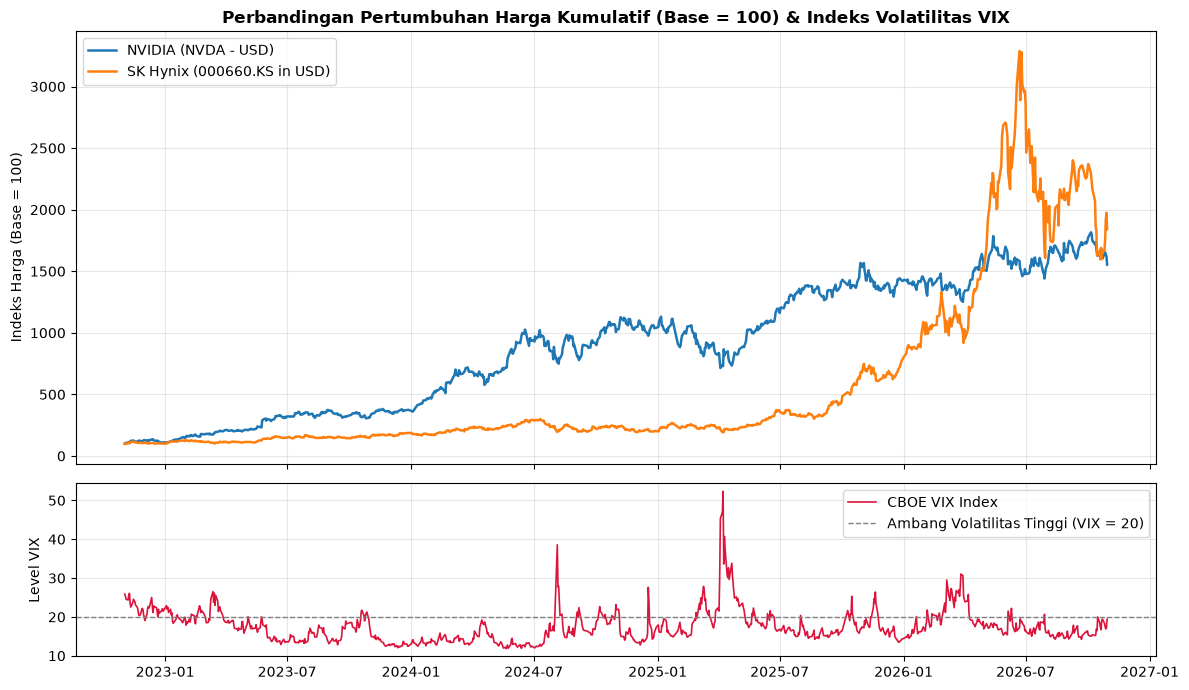

In [21]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [2.5, 1]})

nvda_idx = (df_clean["NVDA_USD"] / df_clean["NVDA_USD"].iloc[0]) * 100
skhy_idx = (df_clean["SKHY_USD"] / df_clean["SKHY_USD"].iloc[0]) * 100

ax1.plot(df_clean.index, nvda_idx, label="NVIDIA (NVDA - USD)", linewidth=1.8)
ax1.plot(df_clean.index, skhy_idx, label="SK Hynix (000660.KS in USD)", linewidth=1.8)
ax1.set_title("Perbandingan Pertumbuhan Harga Kumulatif (Base = 100) & Indeks Volatilitas VIX", fontsize=12, fontweight="bold")
ax1.set_ylabel("Indeks Harga (Base = 100)")
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(df_clean.index, df_clean["VIX"], color="crimson", label="CBOE VIX Index", linewidth=1.2)
ax2.axhline(20, color="gray", linestyle="--", linewidth=1, label="Ambang Volatilitas Tinggi (VIX = 20)")
ax2.set_ylabel("Level VIX")
ax2.legend()
ax2.grid(True, alpha=0.3)
plt.tight_layout()
save_fig("nvda_skhy_vix_comparison.png")
plt.show()

[Saved Figure] -> reports\figures\rolling_correlation_nvda_skhy.png


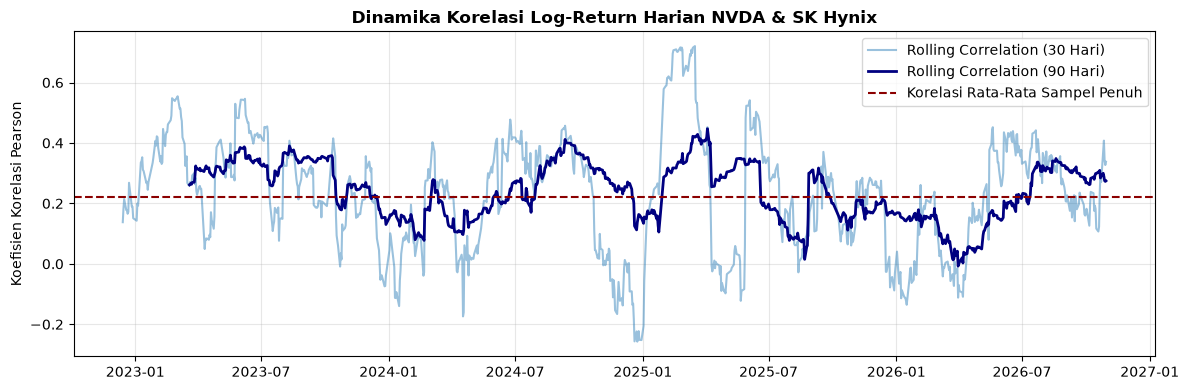

In [22]:
roll_30 = df_clean["r_NVDA"].rolling(30).corr(df_clean["r_SKHY"])
roll_90 = df_clean["r_NVDA"].rolling(90).corr(df_clean["r_SKHY"])

plt.figure(figsize=(12, 4))
plt.plot(df_clean.index, roll_30, alpha=0.45, label="Rolling Correlation (30 Hari)")
plt.plot(df_clean.index, roll_90, linewidth=2, color="navy", label="Rolling Correlation (90 Hari)")
plt.axhline(df_clean["r_NVDA"].corr(df_clean["r_SKHY"]), color="darkred", linestyle="--", label="Korelasi Rata-Rata Sampel Penuh")
plt.title("Dinamika Korelasi Log-Return Harian NVDA & SK Hynix", fontsize=12, fontweight="bold")
plt.ylabel("Koefisien Korelasi Pearson")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
save_fig("rolling_correlation_nvda_skhy.png")
plt.show()

In [18]:
# 4. Perbandingan Korelasi Berdasarkan Rezim VIX (VIX < 20 vs VIX >= 20)
calm_regime = df_clean[df_clean["VIX"] < 20]
panic_regime = df_clean[df_clean["VIX"] >= 20]

print(f"Korelasi Return NVDA-SKHY saat Pasar Tenang (VIX < 20, n={len(calm_regime)}): {calm_regime['r_NVDA'].corr(calm_regime['r_SKHY']):.4f}")
print(f"Korelasi Return NVDA-SKHY saat Pasar Gejolak (VIX >= 20, n={len(panic_regime)}): {panic_regime['r_NVDA'].corr(panic_regime['r_SKHY']):.4f}")

Korelasi Return NVDA-SKHY saat Pasar Tenang (VIX < 20, n=745): 0.2320
Korelasi Return NVDA-SKHY saat Pasar Gejolak (VIX >= 20, n=197): 0.1767


[Saved Table]  -> reports\tables\jarque_bera_normality.csv


,N,JB Statistic,p-value,Skewness,Kurtosis,Kesimpulan
Variabel,,,,,,
ln_NVDA,942,114.964618,0.0,-0.809911,2.447540,Tidak normal
ln_SKHY,942,143.699372,0.0,0.940918,2.653847,Tidak normal
ln_VIX,942,276.615111,0.0,0.945982,4.862255,Tidak normal
r_NVDA,942,1240.065368,0.0,0.507386,8.528495,Tidak normal
r_SKHY,942,407.708240,0.0,0.073507,6.219605,Tidak normal
d_ln_VIX,942,2412.119348,0.0,0.930294,10.615345,Tidak normal


[Saved Figure] -> reports\figures\jarque_bera_distributions.png


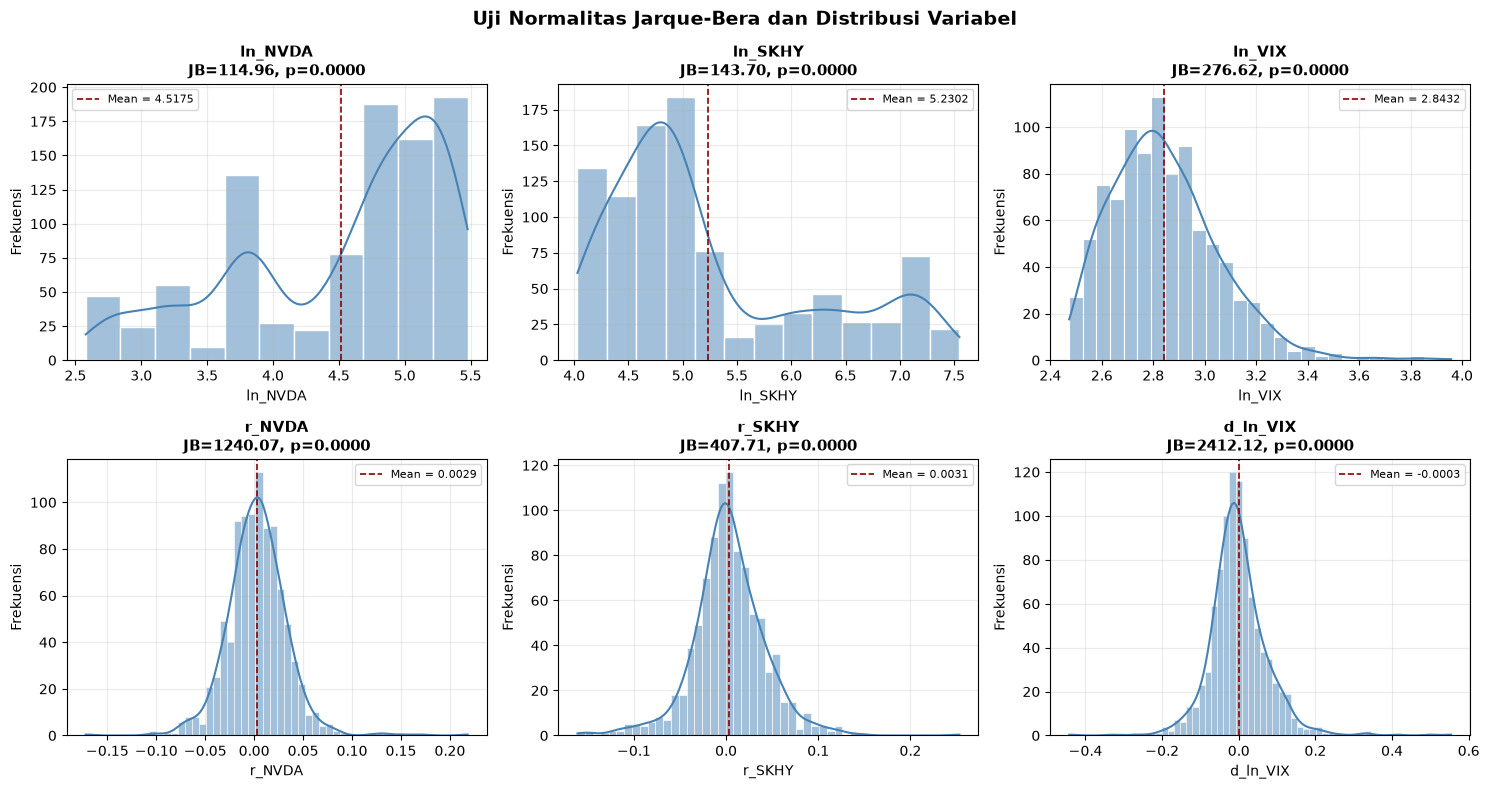

In [23]:

from statsmodels.stats.stattools import jarque_bera

# Uji Jarque-Bera untuk distribusi harga log, return, dan perubahan VIX
cols_normality = ["ln_NVDA", "ln_SKHY", "ln_VIX", "r_NVDA", "r_SKHY", "d_ln_VIX"]
normality_rows = []

for col in cols_normality:
    data = df_clean[col].dropna()
    jb_stat, jb_pvalue, skewness, kurtosis = jarque_bera(data)

    normality_rows.append({
        "Variabel": col,
        "N": len(data),
        "JB Statistic": jb_stat,
        "p-value": jb_pvalue,
        "Skewness": skewness,
        "Kurtosis": kurtosis,
        "Kesimpulan": "Tidak normal" if jb_pvalue < 0.05 else "Normal",
    })

df_normality = pd.DataFrame(normality_rows).set_index("Variabel")
save_table(df_normality.round(6), "jarque_bera_normality.csv")
display(df_normality.round(6))

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()

for ax, col in zip(axes, cols_normality):
    data = df_clean[col].dropna()
    sns.histplot(data, kde=True, ax=ax, color="steelblue", edgecolor="white")

    ax.axvline(data.mean(), color="darkred", linestyle="--", linewidth=1.2,
               label=f"Mean = {data.mean():.4f}")

    row = df_normality.loc[col]
    ax.set_title(
        f"{col}\nJB={row['JB Statistic']:.2f}, p={row['p-value']:.4f}",
        fontsize=11,
        fontweight="bold",
    )
    ax.set_xlabel(col)
    ax.set_ylabel("Frekuensi")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.25)

plt.suptitle("Uji Normalitas Jarque-Bera dan Distribusi Variabel",
             fontsize=14, fontweight="bold")
plt.tight_layout()
save_fig("jarque_bera_distributions.png")
plt.show()


[Saved Figure] -> reports\figures\rolling_correlation_ai_period.png


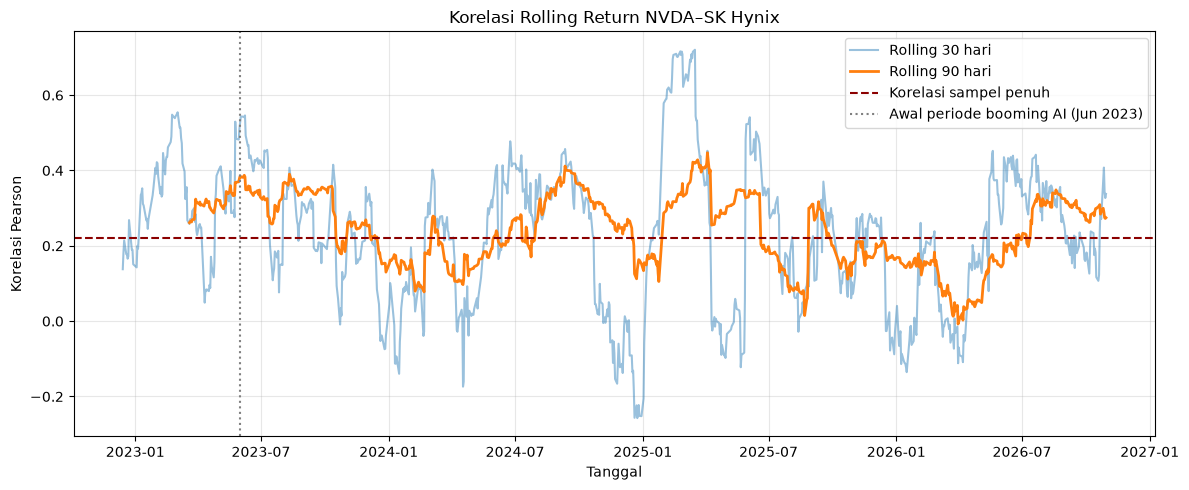

[Saved Table]  -> reports\tables\rolling_correlation_period_summary.csv


,Rata-rata korelasi 30 hari,Rata-rata korelasi 90 hari
Sebelum Jun 2023,0.3129,0.3150
Jun 2023 dan sesudahnya,0.2170,0.2347


: 

In [ ]:
break_date = pd.Timestamp("2023-06-01")

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(roll_30.index, roll_30, alpha=0.45, label="Rolling 30 hari")
ax.plot(roll_90.index, roll_90, linewidth=2, label="Rolling 90 hari")
ax.axhline(
    df_clean["r_NVDA"].corr(df_clean["r_SKHY"]),
    color="darkred",
    linestyle="--",
    label="Korelasi sampel penuh",
)
ax.axvline(
    break_date,
    color="gray",
    linestyle=":",
    label="Awal periode booming AI (Jun 2023)",
)

ax.set(
    title="Korelasi Rolling Return NVDA–SK Hynix",
    xlabel="Tanggal",
    ylabel="Korelasi Pearson",
)
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
save_fig("rolling_correlation_ai_period.png")
plt.show()

period_summary = pd.DataFrame({
    "Rata-rata korelasi 30 hari": [
        roll_30.loc[roll_30.index < break_date].mean(),
        roll_30.loc[roll_30.index >= break_date].mean(),
    ],
    "Rata-rata korelasi 90 hari": [
        roll_90.loc[roll_90.index < break_date].mean(),
        roll_90.loc[roll_90.index >= break_date].mean(),
    ],
}, index=["Sebelum Jun 2023", "Jun 2023 dan sesudahnya"])

save_table(period_summary.round(4), "rolling_correlation_period_summary.csv")
display(period_summary.round(4))